# Phân loại rác bằng EfficientNet-B0
EfficientNet-B0 pretrained ImageNet (compound scaling, MBConv + SE), thay lớp classifier thành 12 lớp và fine-tune toàn bộ.

Dữ liệu: **Garbage Classification** (12 loại rác, ~15.5k ảnh) trong `data/garbage/`.

In [1]:
import torch, torch.nn as nn
from torchvision import models
import common as C
print(C.DEVICE)

cuda


## 1. Dữ liệu

12 lớp: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
{'train': 10864, 'val': 2328, 'test': 2328}


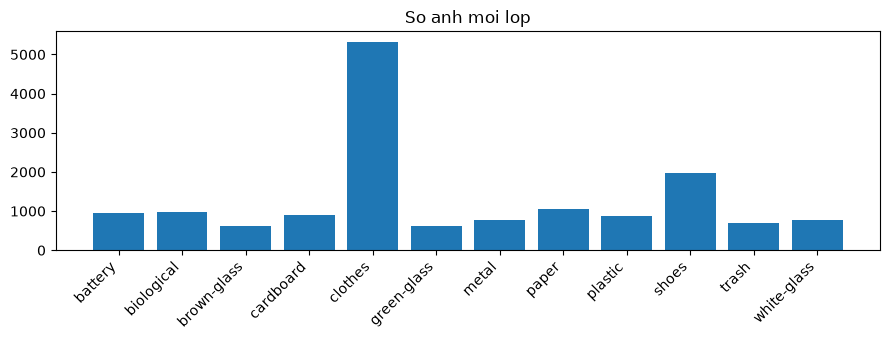

{'battery': 945,
 'biological': 985,
 'brown-glass': 607,
 'cardboard': 891,
 'clothes': 5325,
 'green-glass': 629,
 'metal': 769,
 'paper': 1050,
 'plastic': 865,
 'shoes': 1977,
 'trash': 697,
 'white-glass': 780}

In [2]:
IMG_SIZE, BATCH_SIZE = 128, 64
classes, loaders, y_train = C.get_loaders(IMG_SIZE, BATCH_SIZE)
print(len(classes), 'lớp:', classes)
print({k: len(v.dataset) for k, v in loaders.items()})
C.plot_class_distribution(classes)

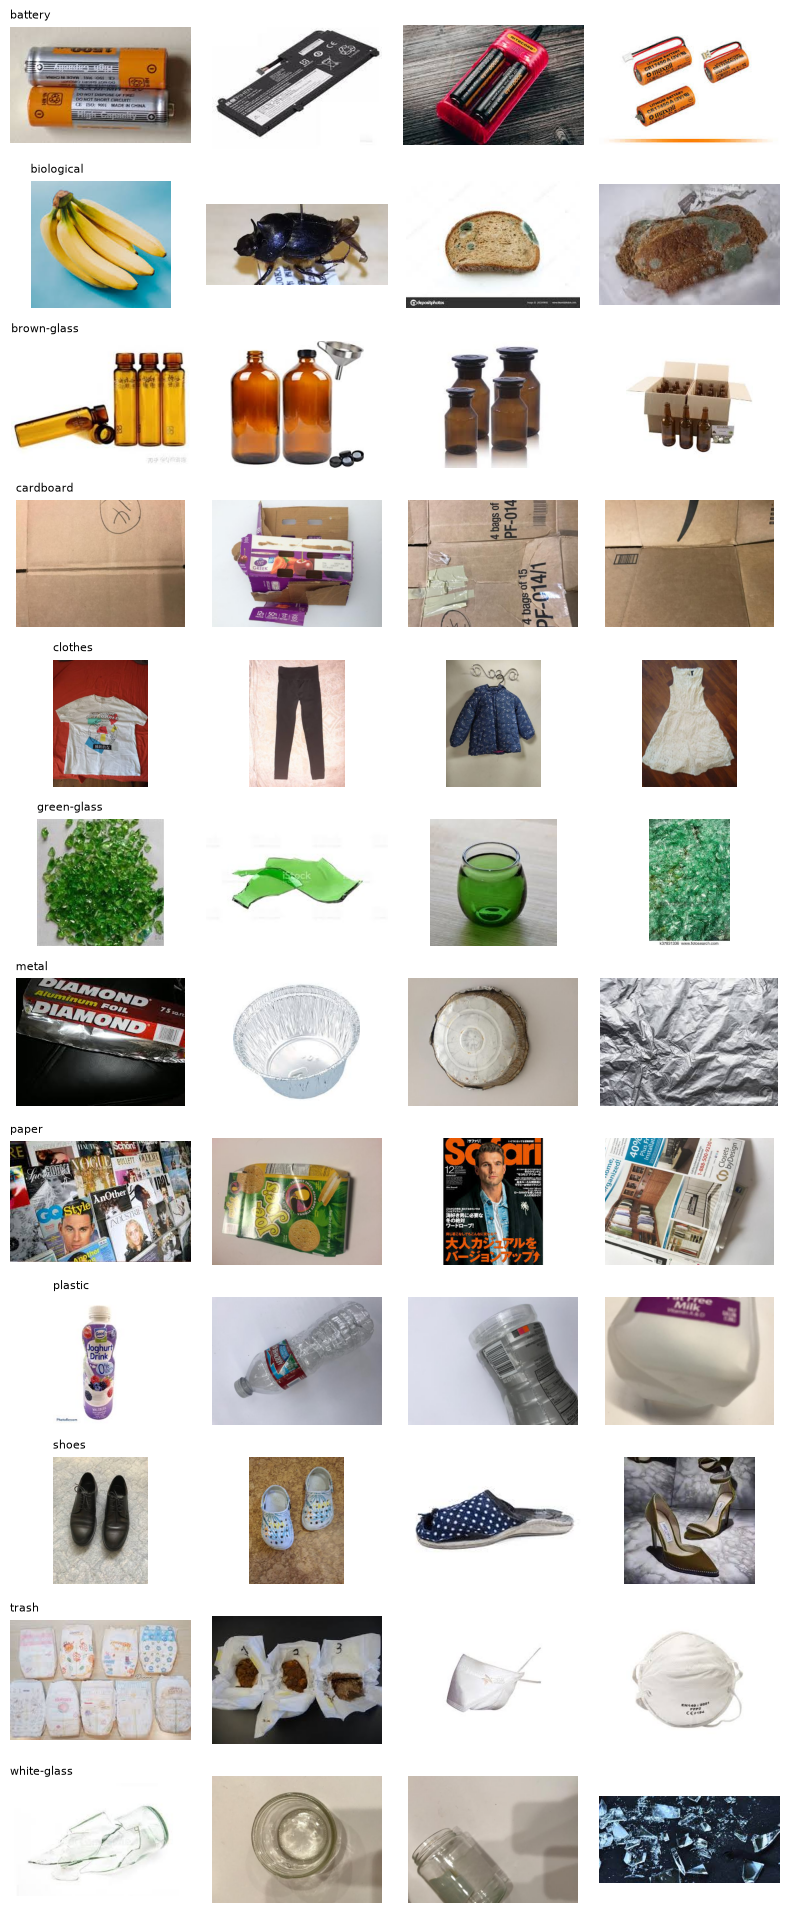

In [3]:
C.show_samples(classes)

## 2. Mô hình

In [4]:
model = models.efficientnet_b0(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(classes))

In [5]:
print(f'{sum(p.numel() for p in model.parameters())/1e6:.2f}M tham số')

4.02M tham số


## 3. Huấn luyện
Dùng AdamW + OneCycleLR, mixed precision, loss có trọng số lớp (dữ liệu mất cân bằng: `clothes` nhiều hơn hẳn các lớp khác). Chọn checkpoint theo val accuracy.

In [6]:
EPOCHS, LR = 10, 0.001
model, hist, t = C.train_model('efficientnet_b0', model, loaders, y_train, len(classes), EPOCHS, LR)
print(f'Thời gian train: {t/60:.1f} phút')

ep 01/10 | train loss 1.516 acc 0.585 | val loss 0.368 acc 0.916
ep 02/10 | train loss 0.346 acc 0.913 | val loss 0.304 acc 0.915
ep 03/10 | train loss 0.342 acc 0.908 | val loss 0.401 acc 0.902
ep 04/10 | train loss 0.248 acc 0.930 | val loss 0.247 acc 0.943
ep 05/10 | train loss 0.172 acc 0.951 | val loss 0.208 acc 0.945
ep 06/10 | train loss 0.117 acc 0.967 | val loss 0.214 acc 0.949
ep 07/10 | train loss 0.074 acc 0.977 | val loss 0.176 acc 0.959
ep 08/10 | train loss 0.041 acc 0.987 | val loss 0.177 acc 0.962
ep 09/10 | train loss 0.026 acc 0.991 | val loss 0.154 acc 0.966
ep 10/10 | train loss 0.022 acc 0.992 | val loss 0.154 acc 0.967
Thời gian train: 8.8 phút


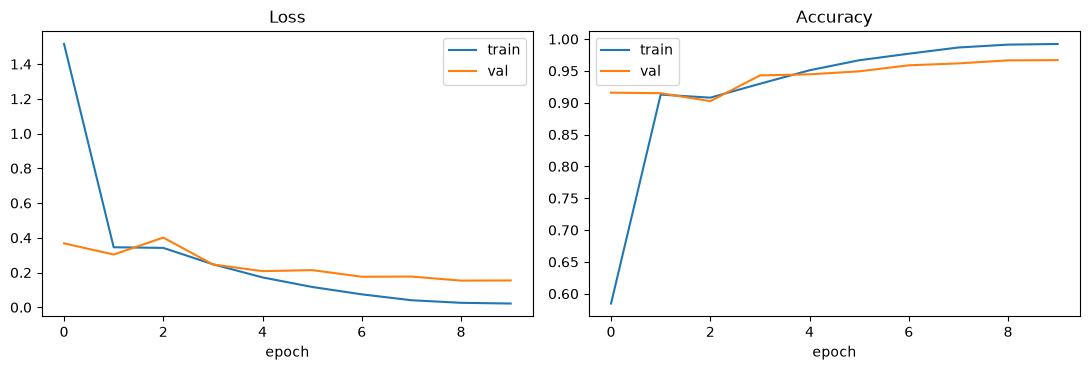

In [7]:
C.plot_history(hist)

## 4. Đánh giá trên tập test

              precision    recall  f1-score   support

     battery     0.9720    0.9789    0.9754       142
  biological     0.9474    0.9796    0.9632       147
 brown-glass     1.0000    0.9670    0.9832        91
   cardboard     0.9531    0.9173    0.9349       133
     clothes     0.9886    0.9800    0.9843       799
 green-glass     1.0000    0.9895    0.9947        95
       metal     0.9145    0.9224    0.9185       116
       paper     0.9264    0.9618    0.9437       157
     plastic     0.9655    0.8615    0.9106       130
       shoes     0.9498    0.9562    0.9530       297
       trash     0.9266    0.9712    0.9484       104
 white-glass     0.8898    0.9658    0.9262       117

    accuracy                         0.9613      2328
   macro avg     0.9528    0.9543    0.9530      2328
weighted avg     0.9620    0.9613    0.9613      2328



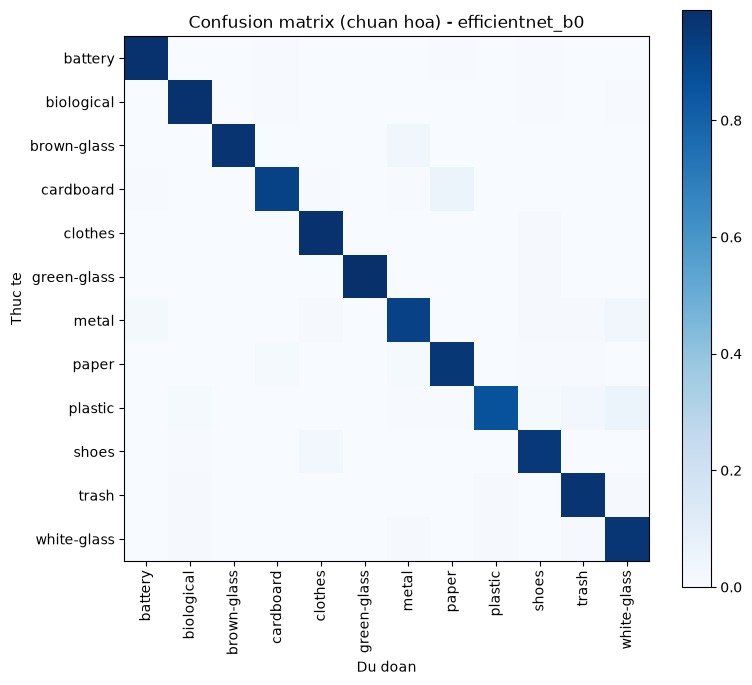

Test accuracy: 0.9613 | macro F1: 0.9530


In [8]:
res = C.evaluate('efficientnet_b0', model, loaders['test'], classes, hist, t)

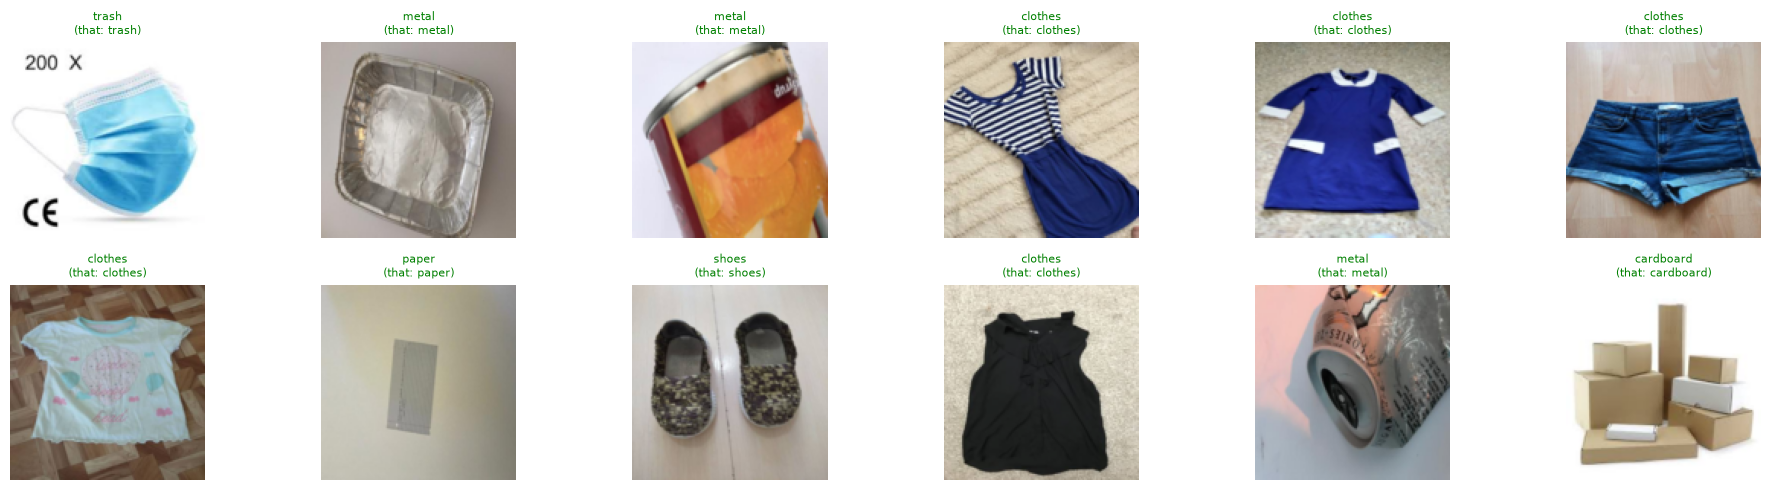

In [9]:
C.show_predictions(model, loaders['test'], classes)

## 5. Nhận xét

**Kết quả:** EfficientNet-B0 đạt **96,1% accuracy** và **macro F1 = 0,953** trên tập test, **tốt nhất trong 3 mô hình**. Mô hình chỉ có 4,02 triệu tham số, train 10 epoch trong khoảng 8,8 phút.

**Quá trình huấn luyện:** val accuracy cao nhất là 96,7%, train accuracy cuối là 99,2%. Chênh lệch khoảng 2,5 điểm, nhỏ hơn ResNet18, nên mô hình tổng quát hóa tốt hơn.

**Theo từng lớp (F1):** gần như mọi lớp đều trên 0,91. Cao nhất là `green-glass` (0,995), `clothes` (0,984), `brown-glass` (0,983) và `battery` (0,975). Thấp nhất vẫn là `plastic` (0,911), `metal` (0,918) và `white-glass` (0,926).

**Lỗi hay gặp:** còn lại chủ yếu là các cặp giống nhau về hình thức: `clothes` đoán thành `shoes` (8 ảnh), `cardboard` đoán thành `paper` (8 ảnh), `plastic` đoán thành `white-glass` (8 ảnh). Số lỗi mỗi cặp giảm rõ so với CNN (33 ảnh cho cặp clothes và shoes) và ResNet18 (17 ảnh).

**Kết luận:** EfficientNet-B0 cho độ chính xác cao nhất dù nhẹ hơn ResNet18. Điều này phù hợp với ý tưởng compound scaling (cân bằng độ sâu, độ rộng và độ phân giải) và các khối MBConv có Squeeze-and-Excitation. Đổi lại, thời gian train mỗi epoch cao hơn một chút (khoảng 53 giây so với 47 giây của ResNet18) do kiến trúc phức tạp hơn.